In [1]:
import sys, time
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.base import clone

from src.preprocess import get_train_test_split, make_model_pipeline, RANDOM_STATE
from src.models import get_models

sns.set_theme(style="whitegrid")

X_train, X_test, y_train, y_test = get_train_test_split("../data/telco_churn.csv")
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
models = get_models(scale_pos_weight)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

In [2]:
def fit_pipeline(pipe, X, y, name):
    """Fit a pipeline; Gradient Boosting gets balanced sample weights."""
    if name == "Gradient Boosting":
        w = compute_sample_weight("balanced", y)
        pipe.fit(X, y, model__sample_weight=w)
    else:
        pipe.fit(X, y)
    return pipe


def metrics_at_threshold(y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred),
        "F1": f1_score(y_true, pred),
        "ROC-AUC": roc_auc_score(y_true, proba),
        "PR-AUC": average_precision_score(y_true, proba),
    }

In [3]:
cv_rows, cv_details = [], {}

for name, model in models.items():
    start = time.time()
    fold_scores = []
    for tr_idx, va_idx in cv.split(X_train, y_train):
        Xtr, Xva = X_train.iloc[tr_idx], X_train.iloc[va_idx]
        ytr, yva = y_train.iloc[tr_idx], y_train.iloc[va_idx]
        pipe = fit_pipeline(make_model_pipeline(clone(model)), Xtr, ytr, name)
        fold_scores.append(metrics_at_threshold(yva, pipe.predict_proba(Xva)[:, 1]))
    fold_df = pd.DataFrame(fold_scores)
    cv_details[name] = fold_df
    row = fold_df.mean().round(4).to_dict()
    row["ROC-AUC std"] = round(fold_df["ROC-AUC"].std(), 4)
    row["Model"] = name
    row["Seconds"] = round(time.time() - start, 1)
    cv_rows.append(row)
    print(f"{name} done in {row['Seconds']}s")

cv_results = (pd.DataFrame(cv_rows).set_index("Model")
              .sort_values("ROC-AUC", ascending=False))
cv_results.to_csv("../reports/model_comparison_cv.csv")
cv_results

Logistic Regression done in 0.7s
Decision Tree done in 0.7s
Random Forest done in 3.2s
Gradient Boosting done in 5.5s
XGBoost done in 2.6s


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,ROC-AUC std,Seconds
Model,,,,,,,,
Logistic Regression,0.7551,0.5255,0.7987,0.6337,0.8484,0.6675,0.0137,0.7
Gradient Boosting,0.7512,0.5205,0.7967,0.6296,0.8461,0.6601,0.0123,5.5
Random Forest,0.7620,0.5360,0.7719,0.6326,0.8453,0.6622,0.0126,3.2
XGBoost,0.7556,0.5273,0.7612,0.6230,0.8392,0.6583,0.0113,2.6
Decision Tree,0.7345,0.4999,0.7826,0.6100,0.8268,0.6089,0.0112,0.7


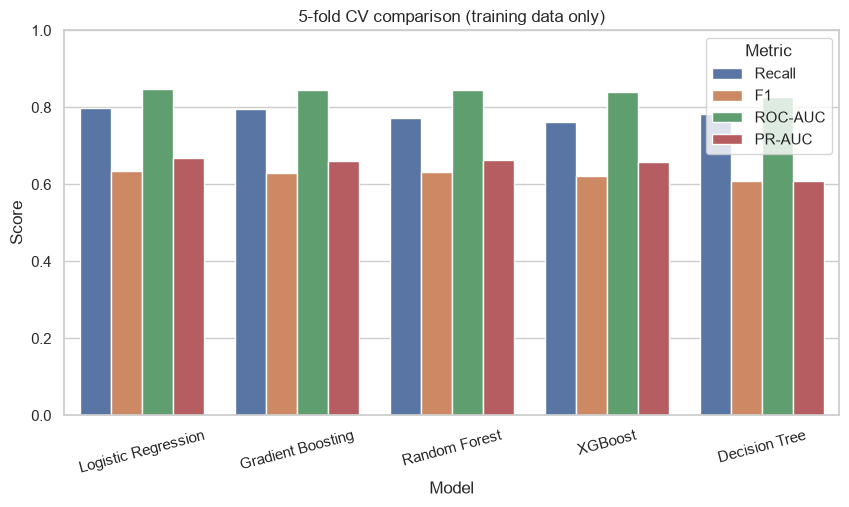

In [4]:
plot_df = cv_results[["Recall", "F1", "ROC-AUC", "PR-AUC"]].reset_index().melt(
    id_vars="Model", var_name="Metric", value_name="Score")

plt.figure(figsize=(10, 5))
sns.barplot(data=plot_df, x="Model", y="Score", hue="Metric")
plt.xticks(rotation=15)
plt.title("5-fold CV comparison (training data only)")
plt.ylim(0, 1)
plt.savefig("../reports/model_comparison_cv.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
fitted, test_rows, test_proba = {}, [], {}

for name, model in models.items():
    pipe = fit_pipeline(make_model_pipeline(clone(model)), X_train, y_train, name)
    fitted[name] = pipe
    proba = pipe.predict_proba(X_test)[:, 1]
    test_proba[name] = proba
    row = {k: round(v, 4) for k, v in metrics_at_threshold(y_test, proba).items()}
    row["Model"] = name
    test_rows.append(row)

test_results = pd.DataFrame(test_rows).set_index("Model").sort_values("ROC-AUC", ascending=False)
test_results.to_csv("../reports/model_comparison_test.csv")
test_results

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Model,,,,,,
Logistic Regression,0.7381,0.5043,0.7754,0.6112,0.8459,0.6613
Gradient Boosting,0.7459,0.5141,0.7807,0.6200,0.8428,0.6589
Random Forest,0.7637,0.5372,0.7914,0.6400,0.8419,0.6504
Decision Tree,0.7537,0.5238,0.7941,0.6312,0.8351,0.6191
XGBoost,0.7495,0.5193,0.7567,0.6159,0.8320,0.6385


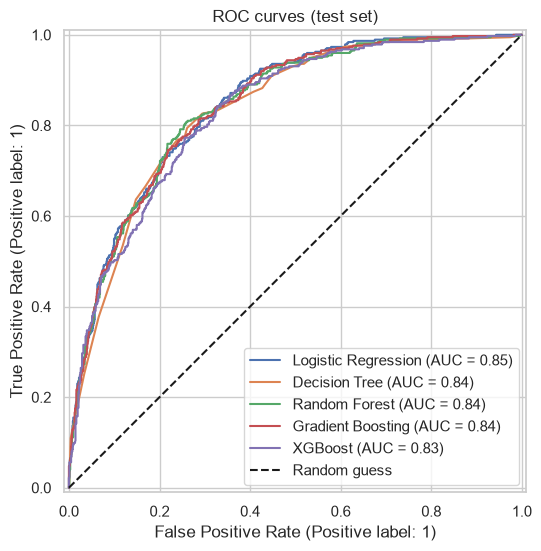

In [6]:
fig, ax = plt.subplots(figsize=(7, 6))
for name, proba in test_proba.items():
    RocCurveDisplay.from_predictions(y_test, proba, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Random guess")
ax.set_title("ROC curves (test set)")
ax.legend(loc="lower right")
plt.savefig("../reports/roc_curves.png", dpi=150, bbox_inches="tight")
plt.show()

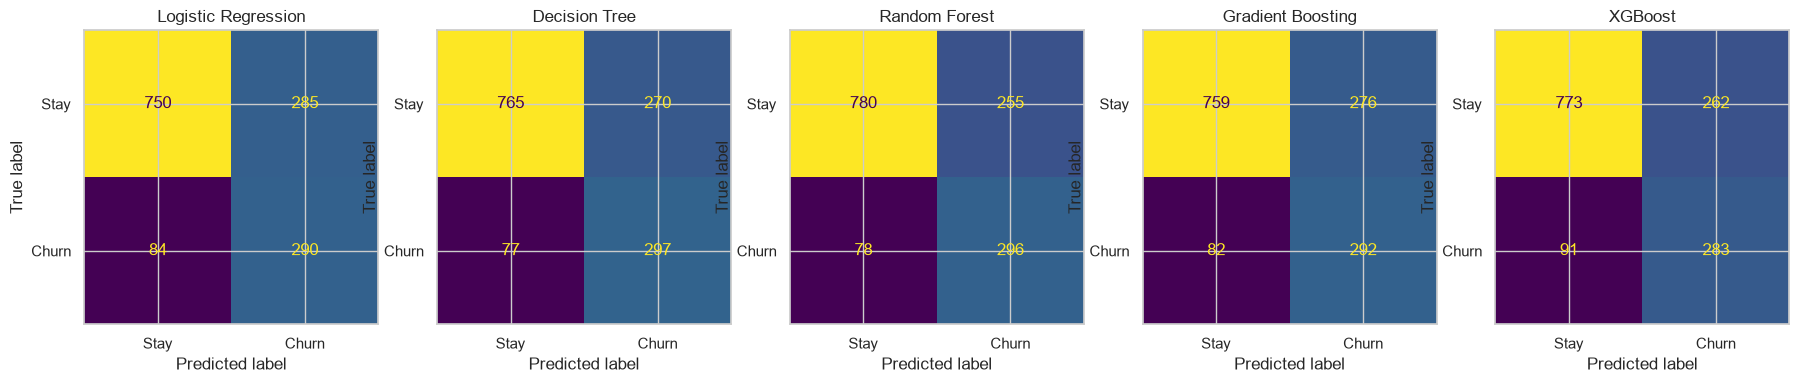

In [7]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, (name, proba) in zip(axes, test_proba.items()):
    pred = (proba >= 0.5).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                           display_labels=["Stay", "Churn"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.savefig("../reports/confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

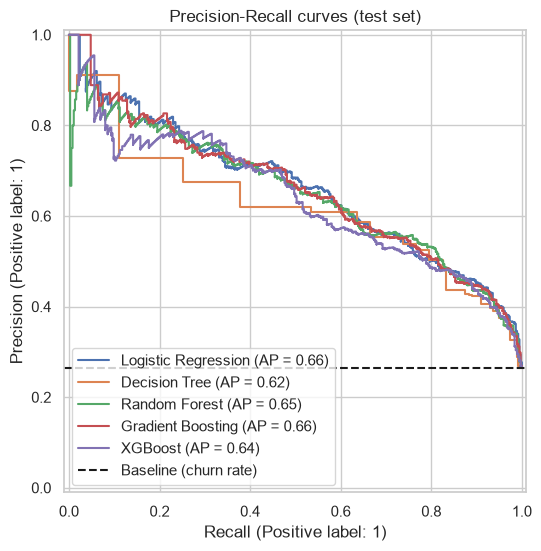

In [8]:
from sklearn.metrics import PrecisionRecallDisplay

fig, ax = plt.subplots(figsize=(7, 6))
for name, proba in test_proba.items():
    PrecisionRecallDisplay.from_predictions(y_test, proba, name=name, ax=ax)
ax.axhline(y_test.mean(), color="k", linestyle="--", label="Baseline (churn rate)")
ax.set_title("Precision-Recall curves (test set)")
ax.legend()
plt.savefig("../reports/pr_curves.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
top2 = cv_results.index[:2].tolist()
print("Tuning:", top2)

Tuning: ['Logistic Regression', 'Gradient Boosting']


In [10]:
param_spaces = {
    "Random Forest": {
        "model__n_estimators": [100, 200, 300],
        "model__max_depth": [6, 8, 10, 12],
        "model__min_samples_leaf": [3, 5, 10, 20],
        "model__max_features": ["sqrt", 0.5],
    },
    "Gradient Boosting": {
        "model__n_estimators": [100, 200, 300],
        "model__learning_rate": [0.03, 0.05, 0.1],
        "model__max_depth": [2, 3, 4],
        "model__subsample": [0.7, 0.85, 1.0],
        "model__min_samples_leaf": [5, 10, 20],
    },
    "XGBoost": {
        "model__n_estimators": [100, 200, 300],
        "model__learning_rate": [0.03, 0.05, 0.1],
        "model__max_depth": [2, 3, 4, 5],
        "model__subsample": [0.7, 0.85, 1.0],
        "model__colsample_bytree": [0.6, 0.8, 1.0],
        "model__min_child_weight": [1, 3, 5],
    },
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10, 100],
    },
    "Decision Tree": {
        "model__max_depth": [3, 4, 5, 6, 8],
        "model__min_samples_leaf": [10, 20, 50],
    },
}

In [11]:
from sklearn.model_selection import RandomizedSearchCV

tuned, tuning_rows = {}, []

for name in top2:
    pipe = make_model_pipeline(clone(models[name]))
    search = RandomizedSearchCV(
        pipe, param_distributions=param_spaces[name],
        n_iter=15, scoring="roc_auc", cv=cv,
        random_state=RANDOM_STATE, n_jobs=-1, refit=True, verbose=1)

    start = time.time()
    if name == "Gradient Boosting":
        search.fit(X_train, y_train,
                   model__sample_weight=compute_sample_weight("balanced", y_train))
    else:
        search.fit(X_train, y_train)

    tuned[name] = search.best_estimator_
    tuning_rows.append({"Model": name,
                        "Default CV ROC-AUC": round(cv_results.loc[name, "ROC-AUC"], 4),
                        "Tuned CV ROC-AUC": round(search.best_score_, 4),
                        "Best params": search.best_params_,
                        "Seconds": round(time.time() - start, 1)})

pd.DataFrame(tuning_rows)

C:\Users\PADMAVATHI\churn-prediction-system\venv\Lib\site-packages\sklearn\model_selection\_search.py:327: UserWarning: The total space of parameters 5 is smaller than n_iter=15. Running 5 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


Fitting 5 folds for each of 5 candidates, totalling 25 fits
Fitting 5 folds for each of 15 candidates, totalling 75 fits


,Model,Default CV ROC-AUC,Tuned CV ROC-AUC,Best params,Seconds
0,Logistic Regression,0.8484,0.8487,{'model__C': 10},7.3
1,Gradient Boosting,0.8461,0.8494,"{'model__subsample': 0.7, 'model__n_estimators...",24.0


In [12]:
import joblib, os
os.makedirs("../models", exist_ok=True)

for name, pipe in tuned.items():
    fname = name.lower().replace(" ", "_")
    joblib.dump(pipe, f"../models/candidate_{fname}.joblib", compress=3)

for f in os.listdir("../models"):
    print(f, round(os.path.getsize(f"../models/{f}") / 1e6, 2), "MB")

candidate_gradient_boosting.joblib 0.08 MB
candidate_logistic_regression.joblib 0.0 MB
